# YOLOv8 — avaliação final no conjunto de teste

Avalia os **experimentos originais concluídos, sem filtros ou operadores de borda**. Experimentos incompletos são pulados e registrados em `skipped_experiments.json`.
Não treina modelos. Os scripts anteriores avaliaram apenas a validação.

Execute no Colab, inclusive com CPU caso a cota de GPU esteja esgotada.
Tenha o `colab_bundle.zip` com o dataset revisado e os experimentos concluídos
em `MyDrive/what-is-the-book-2/runs/grid`. Não é necessário baixar os modelos no PC.
A avaliação lê os checkpoints pelo Drive e salva os relatórios em uma pasta separada.

O modelo principal é escolhido pelo mAP50–95 de **validação antes de abrir o teste**.
Os resultados de teste dos modelos disponíveis são apresentados para comparação final, sem escolher
hiperparâmetros pelo teste. Não ajuste filtros, limiares ou modelos após ver esses
resultados. As variantes da nova grade de preprocessamento não fazem parte desta avaliação.


## 1. Dataset
Envie o mesmo `colab_bundle.zip` usado no treinamento.

In [ ]:
import zipfile
from pathlib import Path

from google.colab import files

uploaded = files.upload()
assert "colab_bundle.zip" in uploaded, "Selecione colab_bundle.zip"
project = Path("/content/what-is-the-book-2")
project.mkdir(exist_ok=True)
with zipfile.ZipFile("colab_bundle.zip") as archive:
    assert all((project / name).resolve().is_relative_to(project) for name in archive.namelist())
    archive.extractall(project)
del uploaded
import os

os.chdir(project)

## 2. Dependências
Ambiente isolado com as versões do lockfile. GPU é opcional.

In [ ]:
import os
import subprocess
import sys

os.environ["MPLBACKEND"] = "Agg"
subprocess.run([sys.executable, "-m", "pip", "install", "uv"], check=True)
subprocess.run(
    ["uv", "sync", "--locked", "--python", "3.13", "--extra", "training", "--no-dev"],
    check=True,
)

## 3. Drive e opções
`DEVICE="cpu"` funciona sem GPU. Se tiver uma GPU disponível no Colab, mude para `"0"`.
Batch 1 reduz consumo de memória; imagens usam a resolução original de cada experimento.
Não execute esta avaliação na GPU local enquanto a grade de preprocessamento estiver rodando.


In [ ]:
from pathlib import Path

from google.colab import drive

drive.mount("/content/drive")
GRID = Path("/content/drive/MyDrive/what-is-the-book-2/runs/grid")
OUTPUT = GRID.parent / "final_test_original"
DATA = project / "data/unified"
DEVICE = "cpu"
BATCH = 1

for i in range(1, 9):
    folder = GRID / f"exp_{i:02d}"
    complete = (folder / "result.json").is_file() and (folder / "weights/best.pt").is_file()
    print(folder.name, "pronto" if complete else "PENDENTE: treinamento/validação incompleto")
print("Relatórios:", OUTPUT)

## 4. Programa de avaliação
A cópia abaixo permite usar o ZIP existente, mesmo que ainda não contenha o novo script.
Confere a identidade do dataset, a separação por grupos, os arquivos de teste e os
checkpoints disponíveis. Salva hashes, versões e parâmetros para reproduzir a avaliação.
Se algum experimento estiver incompleto, ele será pulado. É necessário pelo menos um experimento concluído.

Aplica apenas o redimensionamento/letterbox e a normalização padrão do YOLO;
nenhum filtro, operador de borda ou aumento em tempo de teste.
Usa `conf=0.001`, IoU de NMS `0.7` e no máximo 1000 detecções por imagem.
O limiar baixo permite construir as curvas de precisão e recall e calcular AP;
não representa um limiar escolhido para uso do detector em produção.


In [6]:
EVALUATOR = r'''
"""Evaluate completed original YOLOv8 experiments on the held-out test set."""

import argparse
import csv
import hashlib
import importlib
import json
import os
from pathlib import Path


def digest(path: Path) -> str:
    with path.open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


def save_json(path: Path, value: object) -> None:
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    temporary.replace(path)


def inspect_data(data: Path) -> tuple[str, str, int]:
    manifest_path = data / "manifest.json"
    entries = json.loads(manifest_path.read_text(encoding="utf-8"))
    groups: dict[str, str] = {}
    test = []
    for entry in entries:
        group = str(entry["group"])
        split = entry["split"]
        if group in groups and groups[group] != split:
            raise ValueError(f"Group {group} appears in multiple splits")
        groups[group] = split
        if split == "test":
            test.append(entry)
    if not test:
        raise ValueError("Test split is empty")
    signature = hashlib.sha256()
    expected = set()
    for entry in sorted(test, key=lambda item: item["image"]):
        image = (data / entry["image"]).resolve()
        if not image.is_relative_to((data / "test/images").resolve()):
            raise ValueError("Invalid test image path")
        label = data / "test/labels" / (image.stem + ".txt")
        expected.add(image)
        signature.update(entry["image"].encode())
        signature.update(bytes.fromhex(digest(image)))
        signature.update(bytes.fromhex(digest(label)))
    actual = {p.resolve() for p in (data / "test/images").iterdir() if p.is_file()}
    if actual != expected:
        raise ValueError("Test image directory differs from the manifest")
    return digest(manifest_path), signature.hexdigest(), len(test)


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data", type=Path, required=True)
    parser.add_argument("--grid", type=Path, required=True)
    parser.add_argument("--output", type=Path, required=True)
    parser.add_argument("--device", default="cpu")
    parser.add_argument("--batch", type=int, default=1)
    args = parser.parse_args()
    if args.batch < 1:
        parser.error("Batch must be positive")
    data, grid, output = args.data.resolve(), args.grid.resolve(), args.output.resolve()
    if output == grid or output.is_relative_to(data):
        raise ValueError("Use a separate output directory outside the dataset")
    manifest_hash, test_hash, count = inspect_data(data)
    experiments = []
    skipped = {}
    for number in range(1, 9):
        folder = grid / f"exp_{number:02d}"
        result_path, best = folder / "result.json", folder / "weights/best.pt"
        if not result_path.is_file() or not best.is_file():
            missing = [
                str(path.relative_to(folder)) for path in (result_path, best) if not path.is_file()
            ]
            skipped[folder.name] = missing
            print(f"STATUS | {folder.name}: incomplete; skipping (missing {missing})", flush=True)
            continue
        result = json.loads(result_path.read_text(encoding="utf-8"))
        if result["dataset_sha256"] != manifest_hash:
            raise ValueError(f"{folder.name}: dataset differs from the training manifest")
        experiments.append((folder.name, result, best))
    output.mkdir(parents=True, exist_ok=True)
    save_json(output / "skipped_experiments.json", skipped)
    if not experiments:
        raise RuntimeError("No completed experiments available; nothing to evaluate")
    print(f"STATUS | Evaluating {len(experiments)}/8 completed experiments", flush=True)
    selected = max(experiments, key=lambda e: e[1]["metrics"]["metrics/mAP50-95(B)"])[0]
    os.environ["MPLBACKEND"] = "Agg"
    ultra = importlib.import_module("ultralytics")
    torch = importlib.import_module("torch")
    for name, result, _ in experiments:
        if result["ultralytics"] != ultra.__version__:
            raise ValueError(f"{name}: install ultralytics=={result['ultralytics']}")
    output.mkdir(parents=True, exist_ok=True)
    plan = {
        "selected_by_validation": selected,
        "skipped_experiments": skipped,
        "manifest_sha256": manifest_hash,
        "test_sha256": test_hash,
        "test_images": count,
        "ultralytics": ultra.__version__,
        "torch": torch.__version__,
        "device": args.device,
        "batch": args.batch,
        "conf": 0.001,
        "iou": 0.7,
        "max_det": 1000,
        "half": False,
        "augment": False,
        "checkpoints": {name: digest(best) for name, _, best in experiments},
        "settings": {name: result["settings"] for name, result, _ in experiments},
        "evaluator_sha256": digest(Path(__file__)),
    }
    plan_path = output / "evaluation_plan.json"
    if plan_path.exists() and json.loads(plan_path.read_text(encoding="utf-8")) != plan:
        raise ValueError("Evaluation configuration changed; choose a new output directory")
    save_json(plan_path, plan)  # Selection is frozen before any test inference.
    yaml = output / "test_dataset.yaml"
    yaml.write_text(
        f"path: {json.dumps(data.as_posix())}\ntrain: train/images\nval: val/images\n"
        "test: test/images\nnames: [book]\nnc: 1\n",
        encoding="utf-8",
    )
    rows = []
    for name, result, best in experiments:
        destination = output / name
        destination.mkdir(exist_ok=True)
        summary = destination / "test_metrics.json"
        if summary.exists():
            saved = json.loads(summary.read_text(encoding="utf-8"))
            print(f"STATUS | {name}: test already evaluated; skipping", flush=True)
        else:
            print(f"STATUS | {name}: evaluating {count} test images", flush=True)
            metrics = ultra.YOLO(str(best)).val(
                data=str(yaml),
                split="test",
                imgsz=result["settings"]["imgsz"],
                batch=args.batch,
                device=args.device,
                workers=0,
                conf=0.001,
                iou=0.7,
                max_det=1000,
                half=False,
                augment=False,
                plots=True,
                project=str(destination),
                name="plots",
                exist_ok=True,
                verbose=False,
            )
            saved = {
                "metrics": {k: float(v) for k, v in metrics.results_dict.items()},
                "speed_ms_per_image": {k: float(v) for k, v in metrics.speed.items()},
            }
            save_json(summary, saved)
        rows.append(
            {
                "experiment": name,
                "selected_by_validation": name == selected,
                "imgsz": result["settings"]["imgsz"],
                "lr0": result["settings"]["lr0"],
                "mosaic": result["settings"]["mosaic"],
                "val_mAP50_95": result["metrics"]["metrics/mAP50-95(B)"],
                "test_precision": saved["metrics"]["metrics/precision(B)"],
                "test_recall": saved["metrics"]["metrics/recall(B)"],
                "test_mAP50": saved["metrics"]["metrics/mAP50(B)"],
                "test_mAP50_95": saved["metrics"]["metrics/mAP50-95(B)"],
            }
        )
        save_json(output / "comparison.json", rows)
        with (output / "comparison.csv").open("w", newline="", encoding="utf-8") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)
    print(f"STATUS | Finished. Model selected on validation: {selected}. Reports: {output}")


if __name__ == "__main__":
    main()
'''
worker = project / "evaluate_final_test.py"
worker.write_text(EVALUATOR, encoding="utf-8")

7842

## 5. Avaliar os modelos concluídos
O log completo fica no Drive. O notebook imprime somente o progresso entre modelos.
Em CPU cada avaliação pode demorar; o log permite acompanhar os lotes.
Ao executar novamente, resultados completos e compatíveis são reutilizados.
Uma avaliação interrompida recomeça apenas para o modelo ainda incompleto.
Não execute duas sessões simultâneas sobre a mesma pasta.


In [7]:
from datetime import datetime

OUTPUT.mkdir(parents=True, exist_ok=True)
log = OUTPUT / f"evaluation_{datetime.now():%Y%m%d_%H%M%S}.log"
command = [
    "uv",
    "run",
    "--no-sync",
    "python",
    "-u",
    str(worker),
    "--data",
    str(DATA),
    "--grid",
    str(GRID),
    "--output",
    str(OUTPUT),
    "--device",
    DEVICE,
    "--batch",
    str(BATCH),
]
print("Log:", log, flush=True)
with log.open("w", encoding="utf-8") as handle:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
    )
    try:
        for line in process.stdout:
            handle.write(line)
            handle.flush()
            if "STATUS |" in line:
                print(line.strip(), flush=True)
        code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        try:
            process.wait(timeout=15)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()
        raise
if code:
    print("".join(log.read_text(encoding="utf-8").splitlines(keepends=True)[-35:]))
    raise RuntimeError(f"Avaliação interrompida (código {code}); consulte o log.")

Log: /content/drive/MyDrive/what-is-the-book-2/runs/final_test_original/evaluation_20261115_215043.log
STATUS | exp_07: incomplete; skipping (missing ['result.json'])
STATUS | exp_08: incomplete; skipping (missing ['result.json', 'weights/best.pt'])
STATUS | Evaluating 6/8 completed experiments
STATUS | exp_01: evaluating 489 test images
STATUS | exp_02: evaluating 489 test images
STATUS | exp_03: evaluating 489 test images
STATUS | exp_04: evaluating 489 test images
STATUS | exp_05: evaluating 489 test images
STATUS | exp_06: evaluating 489 test images
STATUS | Finished. Model selected on validation: exp_05. Reports: /content/drive/MyDrive/what-is-the-book-2/runs/final_test_original


## 6. Resultados finais
Métricas entre 0 e 1, exibidas em porcentagem abaixo. Precisão e recall seguem o
ponto de operação calculado pelo validador; mAP50–95 é a métrica principal.
A ordem é a dos experimentos, não um ranking escolhido pelo teste.

A seleção considera somente os experimentos concluídos desta execução. Para incluir modelos finalizados posteriormente, use outra pasta `OUTPUT`; o plano anterior permanece preservado.


In [8]:
import json

from IPython.display import Markdown, display

rows = json.loads((OUTPUT / "comparison.json").read_text(encoding="utf-8"))
plan = json.loads((OUTPUT / "evaluation_plan.json").read_text(encoding="utf-8"))
print("Imagens de teste:", plan["test_images"])
print("Modelo escolhido pela validação:", plan["selected_by_validation"])
table = [
    "| Experimento | Resolução | Val mAP50–95 | Teste P | Teste R | Teste mAP50 | Teste mAP50–95 |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for row in rows:
    name = row["experiment"] + (" ★" if row["selected_by_validation"] else "")
    keys = ["val_mAP50_95", "test_precision", "test_recall", "test_mAP50", "test_mAP50_95"]
    values = " | ".join(f"{100 * row[key]:.2f}%" for key in keys)
    table.append(f"| {name} | {row['imgsz']} | {values} |")
display(Markdown("\n".join(table)))
print("CSV:", OUTPUT / "comparison.csv")

Imagens de teste: 489
Modelo escolhido pela validação: exp_05


| Experimento | Resolução | Val mAP50–95 | Teste P | Teste R | Teste mAP50 | Teste mAP50–95 |
|---|---:|---:|---:|---:|---:|---:|
| exp_01 | 640 | 84.25% | 91.33% | 86.15% | 93.48% | 75.30% |
| exp_02 | 640 | 83.56% | 90.17% | 86.54% | 93.76% | 74.36% |
| exp_03 | 640 | 83.00% | 90.62% | 86.05% | 93.81% | 74.14% |
| exp_04 | 640 | 82.14% | 90.64% | 86.74% | 94.01% | 73.75% |
| exp_05 ★ | 960 | 85.21% | 91.29% | 87.75% | 94.30% | 76.76% |
| exp_06 | 960 | 84.90% | 91.17% | 88.27% | 95.09% | 76.92% |

CSV: /content/drive/MyDrive/what-is-the-book-2/runs/final_test_original/comparison.csv


## 7. Gráficos e exemplos do modelo selecionado
São exibidas algumas imagens geradas pelo validador. Os arquivos completos ficam
em `<experimento>/plots`, incluindo matriz de confusão, curvas e exemplos anotados.
Os exemplos visuais são uma amostra, não uma auditoria de todas as imagens.


BoxPR_curve.png


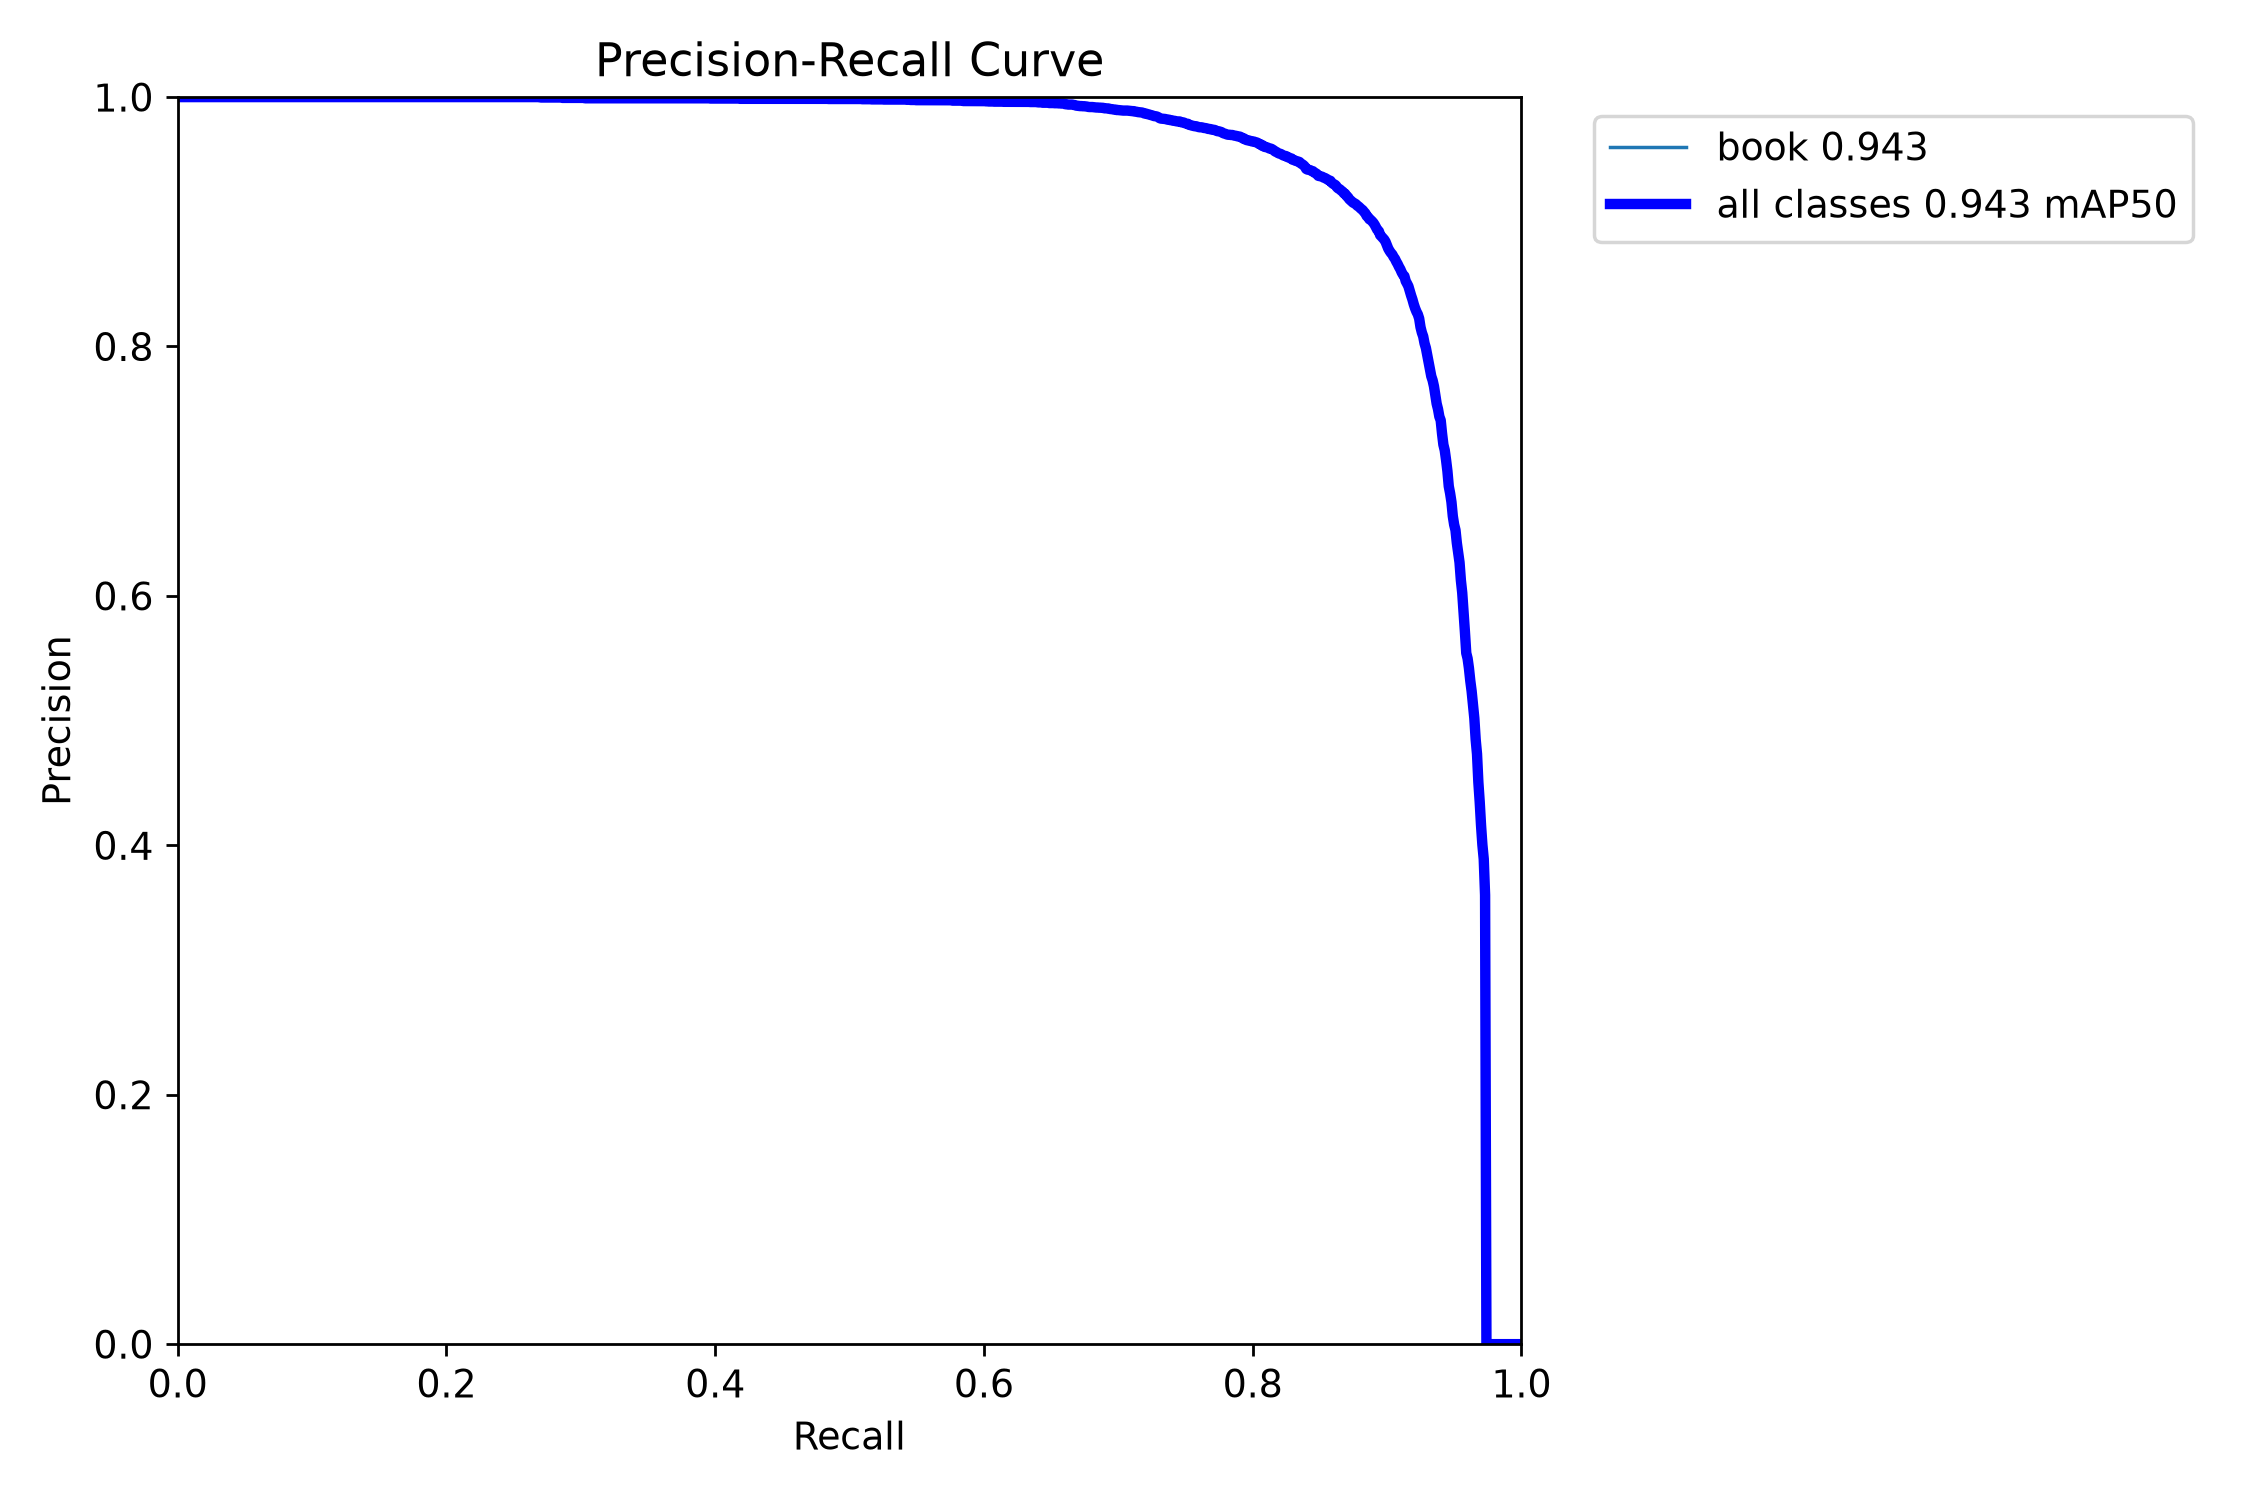

confusion_matrix_normalized.png


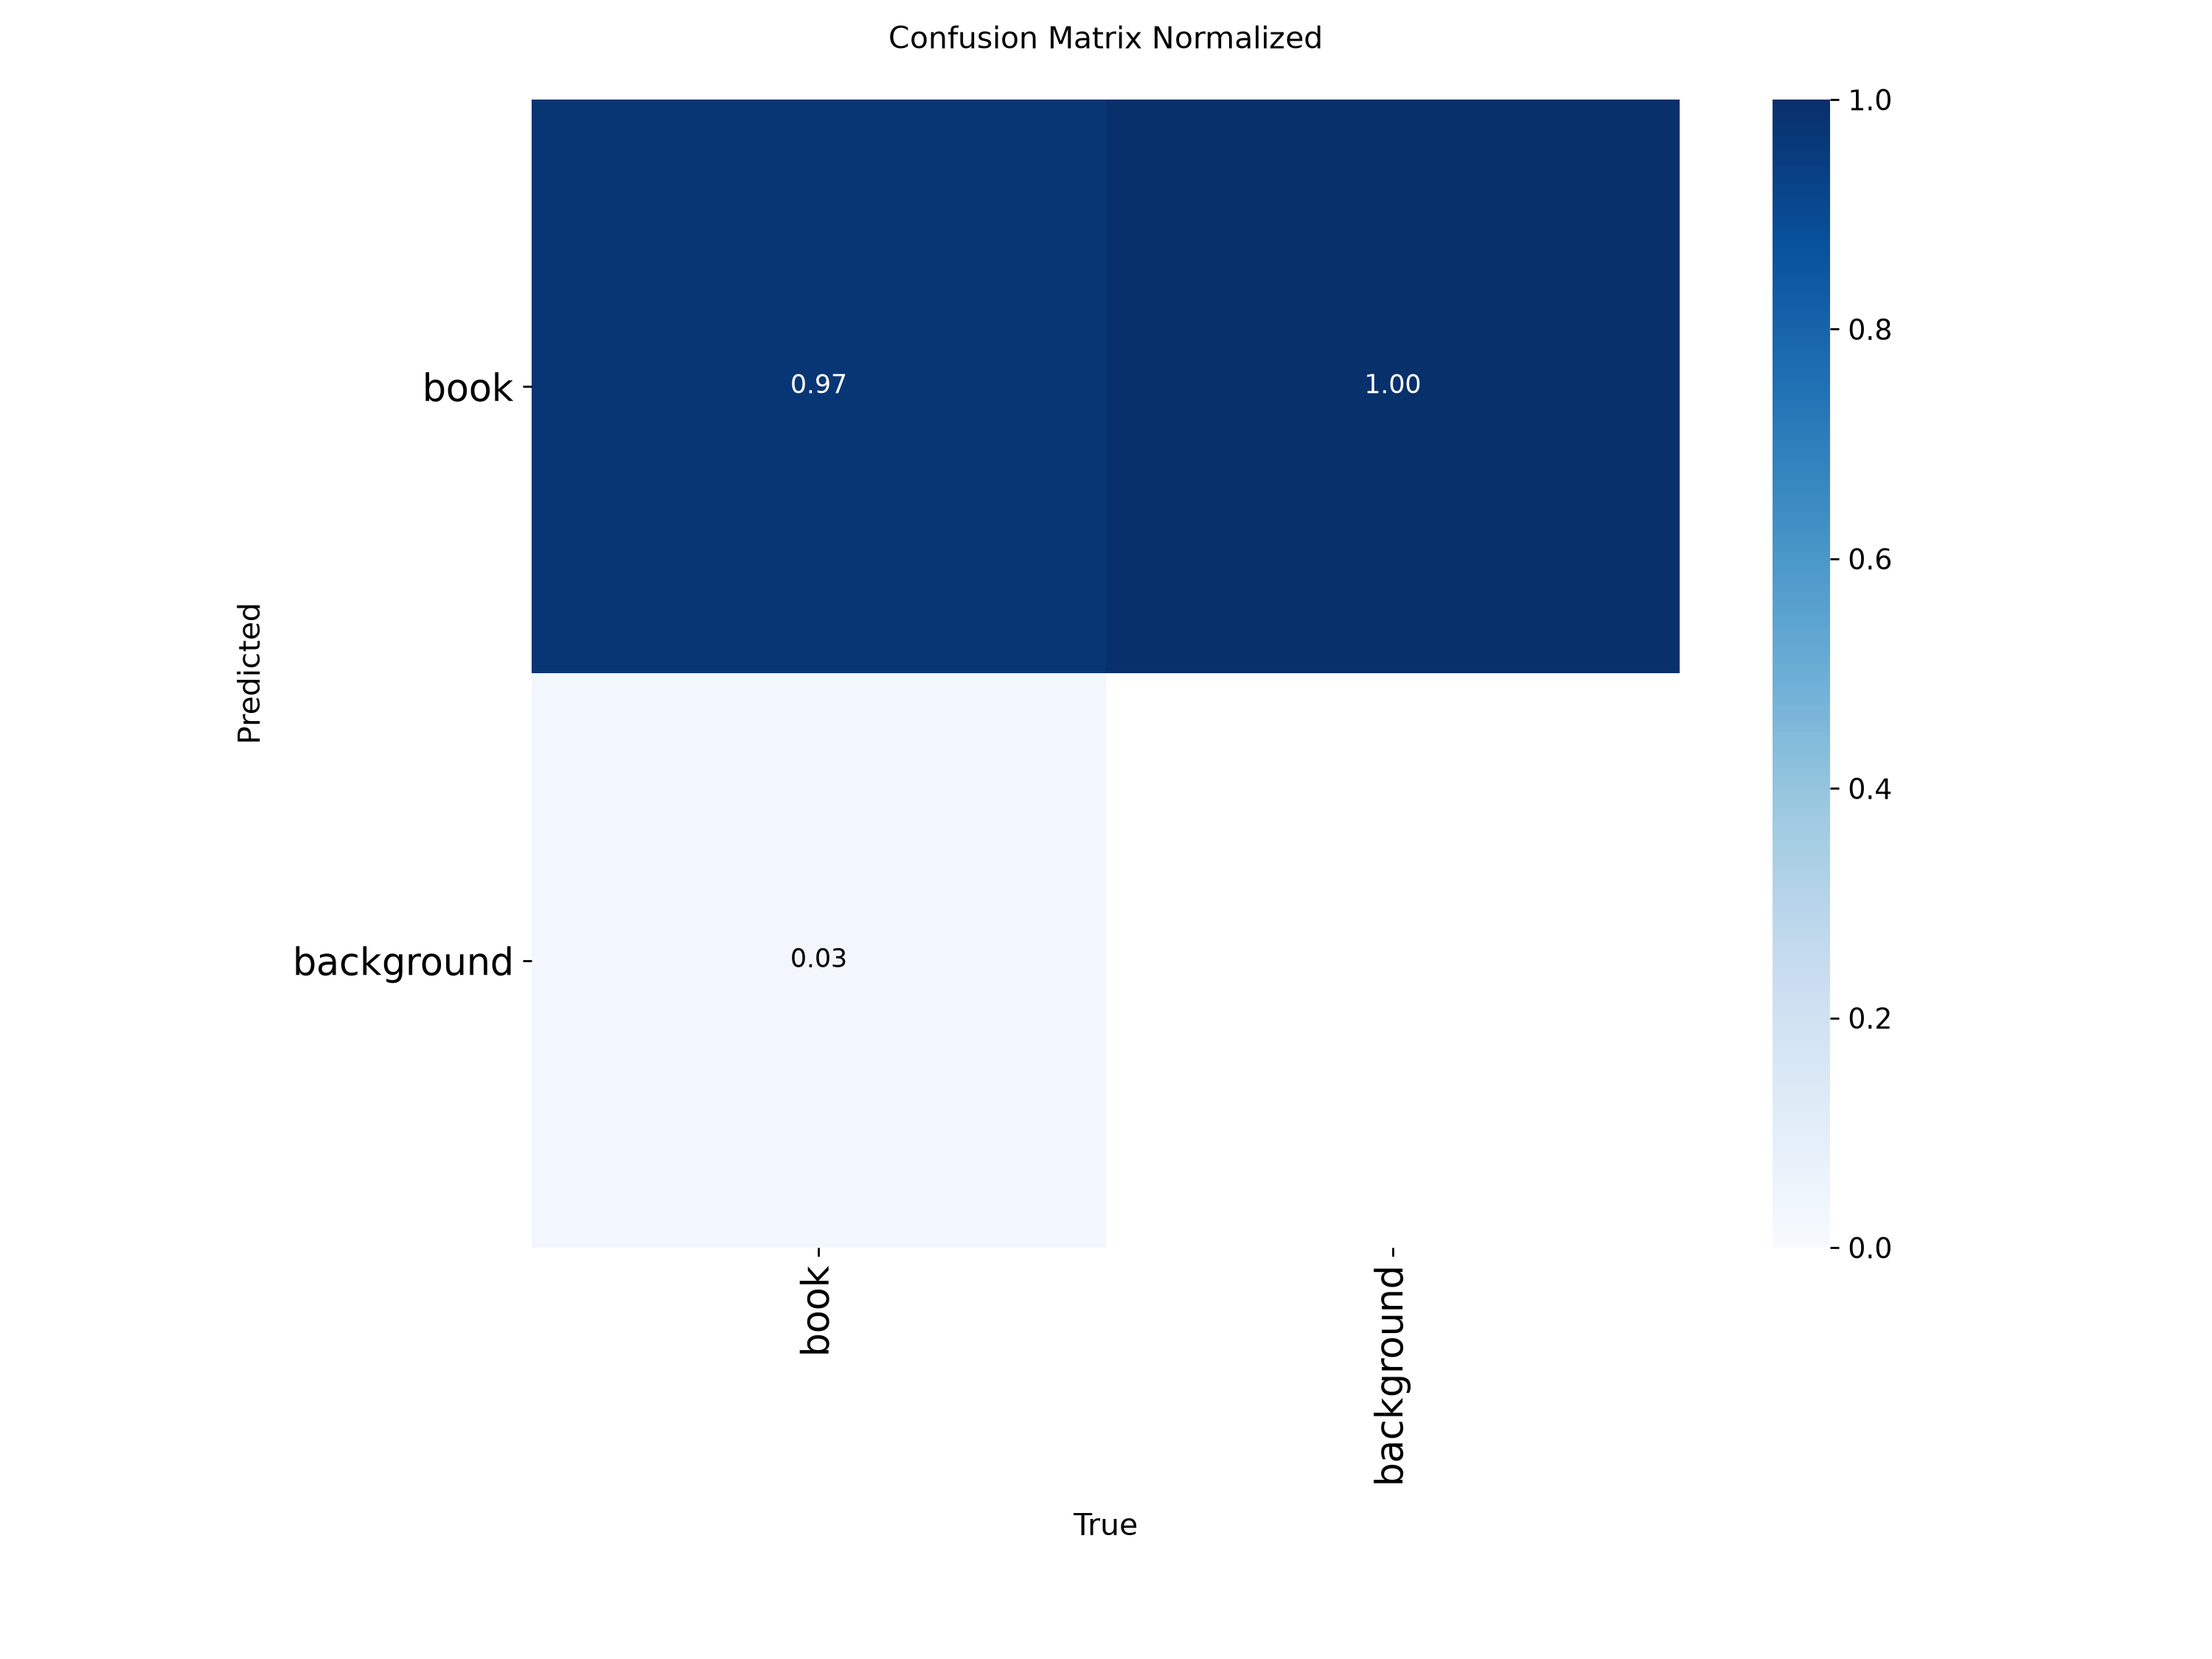

val_batch0_labels.jpg


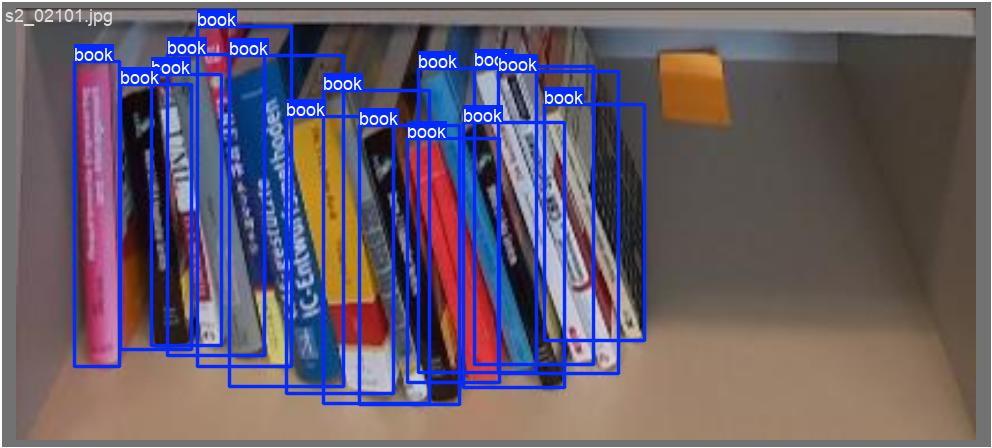

val_batch0_pred.jpg


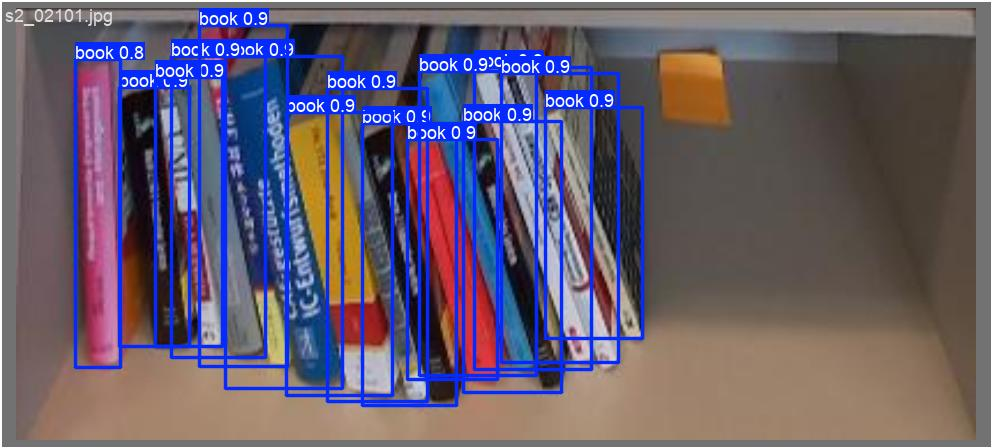

val_batch1_labels.jpg


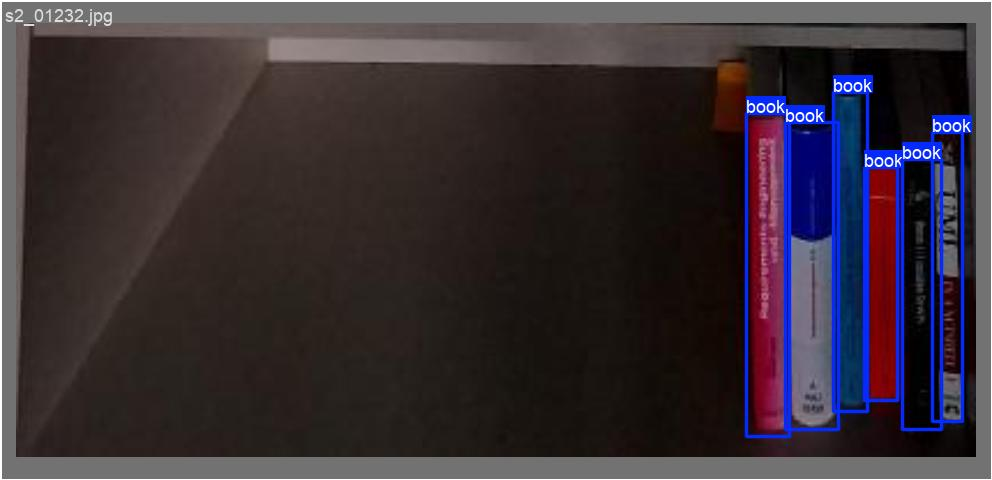

val_batch1_pred.jpg


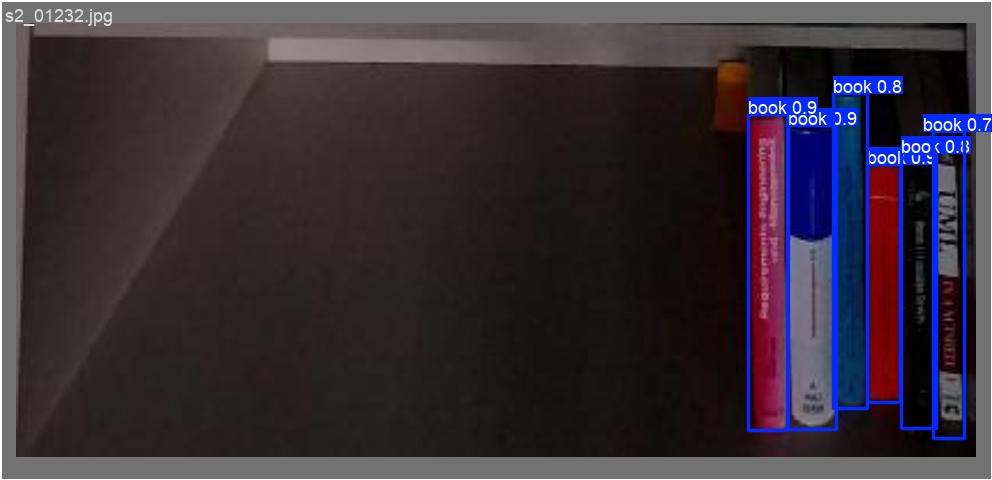

val_batch2_labels.jpg


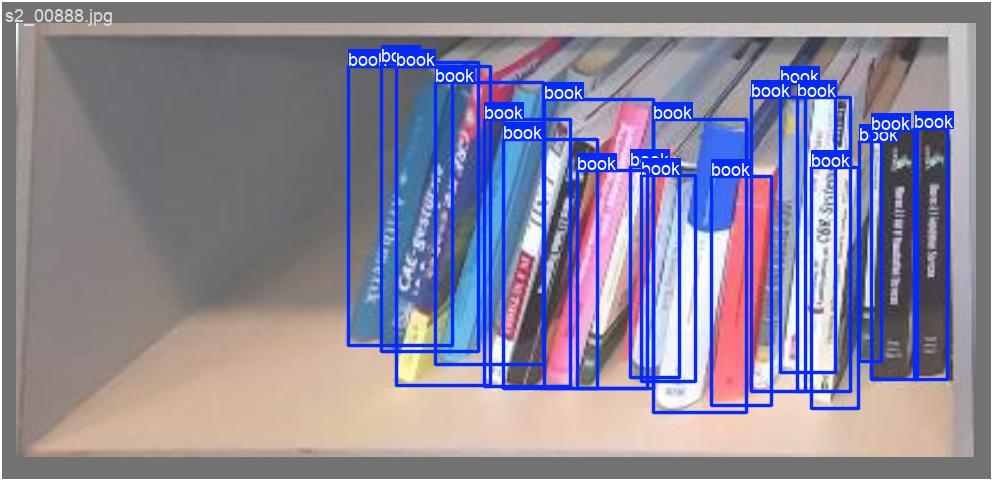

val_batch2_pred.jpg


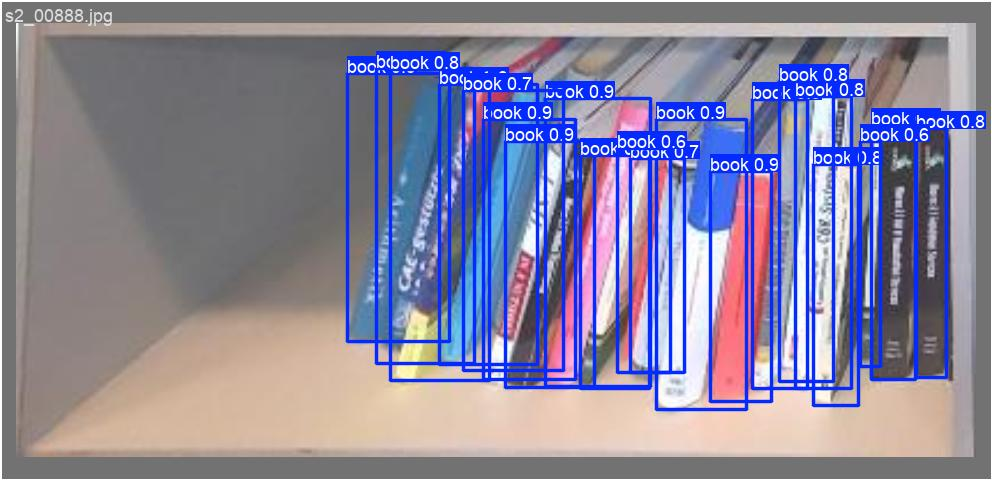

In [17]:
from IPython.display import Image

plots = OUTPUT / plan["selected_by_validation"] / "plots"
for pattern in [
    "*PR_curve.png",
    "confusion_matrix_normalized.png",
    "*batch0_labels.jpg",
    "*batch0_pred.jpg",
    "*batch1_labels.jpg",
    "*batch1_pred.jpg",
    "*batch2_labels.jpg",
    "*batch2_pred.jpg",
]:
    for path in sorted(plots.glob(pattern)):
        print(path.name)
        display(Image(filename=str(path), width=900))